# 5. Heurística com soluções viáveis: um algoritmo genético

In [1]:
from pathlib import Path
import sys, json, numpy as np
ROOT = Path.cwd().resolve()
if not (ROOT / 'optimization_examples').is_dir():
    ROOT = ROOT.parent  # notebooks opened from codes/notebooks/
if not (ROOT / 'optimization_examples').is_dir():
    raise RuntimeError('Abra o notebook a partir do repositório codes ou codes/notebooks.')
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'results' / 'sequence'
OUT.mkdir(parents=True, exist_ok=True)
def save(name, value):
    (OUT / name).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')


Mesmo problema de seleção. Cromossomo: vetor binário. Fitness: prioridade total. Torneio escolhe pais, cruzamento uniforme combina bits, mutação altera escolhas e reparo mantém as capacidades. Elitismo conserva o melhor candidato. Metas negociáveis podem receber penalidades; restrições físicas continuam obrigatórias.

In [2]:
from optimization_examples.selection import stress_instance, repair, audit
instance = stress_instance()
rng = np.random.default_rng(2026)
pai = repair(instance,rng.integers(0,2,250),rng)
mae = repair(instance,rng.integers(0,2,250),rng)
filho = np.where(rng.random(250)<.5,pai,mae)  # cruzamento uniforme
mutar = rng.random(250)<1/250
filho[mutar] = 1-filho[mutar]
filho = repair(instance,filho,rng)
print('Fitness:',float(instance['value']@filho),'auditoria:',audit(instance,filho)['feasible'])

Fitness: 4888.0 auditoria: True


In [3]:
from optimization_examples.selection import stress_instance, greedy, genetic
instance = stress_instance()
baseline = greedy(instance)
ga = genetic(instance, seed=2026, population=50, generations=30)
print('Gulosa:',baseline['objective'],'viável:',baseline['feasible'])
print('Genético:',ga['objective'],'viável:',ga['feasible'],'tempo:',ga['seconds'])
print('Semente/população/gerações:',ga['seed'],ga['population'],ga['generations'])
print('Nenhum certificado de ótimo. O reparo garante viabilidade neste modelo de limites superiores.')
save('genetic.json', dict(greedy=baseline, ga=ga))

Gulosa: 5453.0 viável: True
Genético: 5621.0 viável: True tempo: 1.0551
Semente/população/gerações: 2026 50 30
Nenhum certificado de ótimo. O reparo garante viabilidade neste modelo de limites superiores.


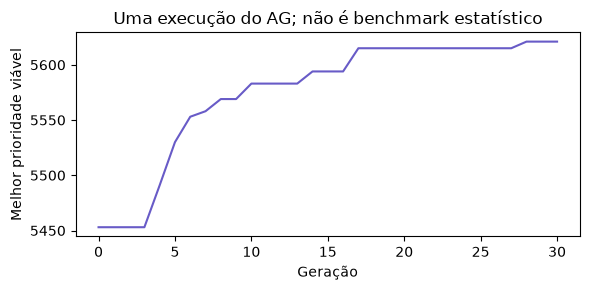

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(ga['history'],color='#685BC7')
ax.set(xlabel='Geração',ylabel='Melhor prioridade viável',title='Uma execução do AG; não é benchmark estatístico')
fig.tight_layout(); fig.savefig(OUT/'ga-history.pdf'); plt.show()